In [2]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Stage": [
        "Visit",
        "Product View",
        "Add to Cart",
        "Purchase"
    ],
    "Users": [
        10000,
        7500,
        3500,
        1200
    ]
}

df = pd.DataFrame(data)

print("E-commerce Conversion Funnel Analysis")
print()
print(df)

E-commerce Conversion Funnel Analysis

          Stage  Users
0         Visit  10000
1  Product View   7500
2   Add to Cart   3500
3      Purchase   1200


In [3]:
df["Drop-off"] = df["Users"].shift(1) - df["Users"]

df.loc[0, "Drop-off"] = 0

print(df)

          Stage  Users  Drop-off
0         Visit  10000       0.0
1  Product View   7500    2500.0
2   Add to Cart   3500    4000.0
3      Purchase   1200    2300.0


In [4]:
df["Conversion Rate (%)"] = (df["Users"] / df["Users"].iloc[0]) * 100

print(df)

          Stage  Users  Drop-off  Conversion Rate (%)
0         Visit  10000       0.0                100.0
1  Product View   7500    2500.0                 75.0
2   Add to Cart   3500    4000.0                 35.0
3      Purchase   1200    2300.0                 12.0


In [5]:
df["Stage Conversion Rate (%)"] = (
    df["Users"] / df["Users"].shift(1)
) * 100

df.loc[0, "Stage Conversion Rate (%)"] = 100

print(df)

          Stage  Users  Drop-off  Conversion Rate (%)  \
0         Visit  10000       0.0                100.0   
1  Product View   7500    2500.0                 75.0   
2   Add to Cart   3500    4000.0                 35.0   
3      Purchase   1200    2300.0                 12.0   

   Stage Conversion Rate (%)  
0                 100.000000  
1                  75.000000  
2                  46.666667  
3                  34.285714  


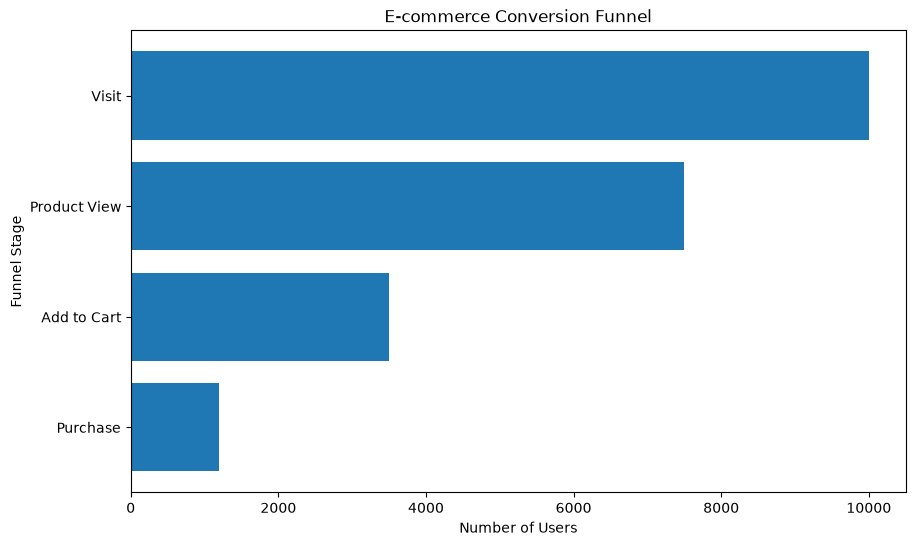

In [6]:
plt.figure(figsize=(10, 6))

plt.barh(df["Stage"], df["Users"])

plt.xlabel("Number of Users")
plt.ylabel("Funnel Stage")
plt.title("E-commerce Conversion Funnel")

plt.gca().invert_yaxis()

plt.show()

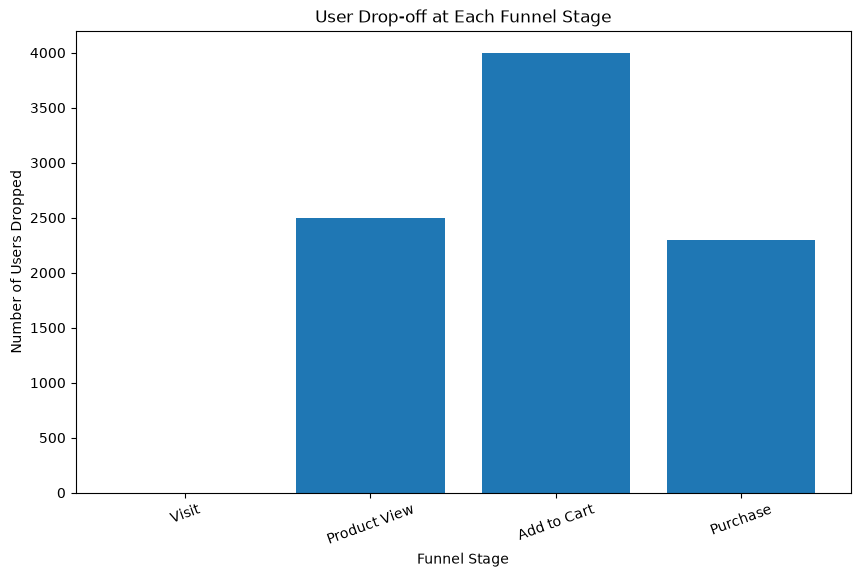

In [7]:
plt.figure(figsize=(10, 6))

plt.bar(df["Stage"], df["Drop-off"])

plt.xlabel("Funnel Stage")
plt.ylabel("Number of Users Dropped")
plt.title("User Drop-off at Each Funnel Stage")

plt.xticks(rotation=20)

plt.show()

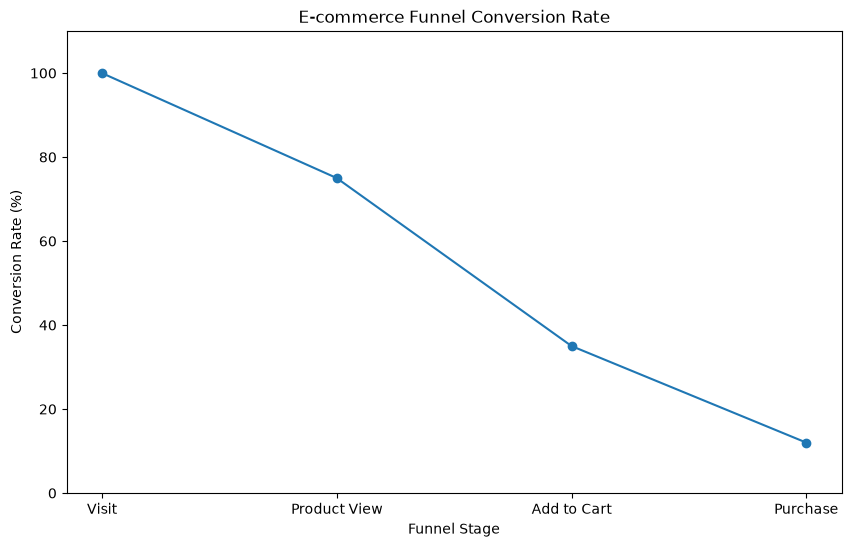

In [8]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["Stage"],
    df["Conversion Rate (%)"],
    marker="o"
)

plt.xlabel("Funnel Stage")
plt.ylabel("Conversion Rate (%)")
plt.title("E-commerce Funnel Conversion Rate")

plt.ylim(0, 110)

plt.show()

In [9]:
max_dropoff = df["Drop-off"].iloc[1:].max()

bottleneck = df.loc[
    df["Drop-off"] == max_dropoff,
    "Stage"
].iloc[0]

print("E-commerce Funnel Analysis")
print("---------------------------")
print("Largest user drop-off:", int(max_dropoff))
print("Bottleneck stage:", bottleneck)
print("Overall conversion rate:", df["Conversion Rate (%)"].iloc[-1], "%")

E-commerce Funnel Analysis
---------------------------
Largest user drop-off: 4000
Bottleneck stage: Add to Cart
Overall conversion rate: 12.0 %


In [10]:
print("FINAL PROJECT FINDINGS")
print("======================")

print("1. Total visitors:", int(df["Users"].iloc[0]))
print("2. Product viewers:", int(df["Users"].iloc[1]))
print("3. Users who added products to cart:", int(df["Users"].iloc[2]))
print("4. Completed purchases:", int(df["Users"].iloc[3]))

print()
print("5. Overall conversion rate:",
      round(df["Conversion Rate (%)"].iloc[-1], 2), "%")

print("6. Largest drop-off:",
      int(df["Drop-off"].iloc[1:].max()), "users")

print("7. Bottleneck: Product View → Add to Cart")

print()
print("RECOMMENDATIONS")
print("---------------")
print("1. Improve product descriptions and images.")
print("2. Make the Add to Cart button more visible.")
print("3. Display clear pricing and product information.")
print("4. Reduce unnecessary steps before adding to cart.")
print("5. Test different product pages to improve engagement.")

FINAL PROJECT FINDINGS
1. Total visitors: 10000
2. Product viewers: 7500
3. Users who added products to cart: 3500
4. Completed purchases: 1200

5. Overall conversion rate: 12.0 %
6. Largest drop-off: 4000 users
7. Bottleneck: Product View → Add to Cart

RECOMMENDATIONS
---------------
1. Improve product descriptions and images.
2. Make the Add to Cart button more visible.
3. Display clear pricing and product information.
4. Reduce unnecessary steps before adding to cart.
5. Test different product pages to improve engagement.


In [11]:
print("==========================================")
print("   E-COMMERCE CONVERSION FUNNEL ANALYSIS")
print("==========================================")

print()
print("FUNNEL SUMMARY")
print("----------------------------")

for i in range(len(df)):
    print(
        df["Stage"].iloc[i],
        ":", int(df["Users"].iloc[i]),
        "users | Overall Conversion:",
        round(df["Conversion Rate (%)"].iloc[i], 2), "%"
    )

print()
print("KEY METRICS")
print("----------------------------")

print("Total Visitors:", int(df["Users"].iloc[0]))
print("Total Purchases:", int(df["Users"].iloc[-1]))
print(
    "Overall Conversion Rate:",
    round(df["Conversion Rate (%)"].iloc[-1], 2),
    "%"
)

print()
print("DROP-OFF ANALYSIS")
print("----------------------------")

for i in range(1, len(df)):
    print(
        df["Stage"].iloc[i-1],
        "->",
        df["Stage"].iloc[i],
        ":",
        int(df["Drop-off"].iloc[i]),
        "users dropped"
    )

print()
print("BOTTLENECK")
print("----------------------------")
print("Product View -> Add to Cart")

print()
print("RECOMMENDATIONS")
print("----------------------------")
print("1. Improve product images and descriptions.")
print("2. Make the Add to Cart button more visible.")
print("3. Provide clear pricing and product information.")
print("4. Simplify the shopping process.")
print("5. Test different product pages to improve conversion.")

print()
print("PROJECT COMPLETED")

   E-COMMERCE CONVERSION FUNNEL ANALYSIS

FUNNEL SUMMARY
----------------------------
Visit : 10000 users | Overall Conversion: 100.0 %
Product View : 7500 users | Overall Conversion: 75.0 %
Add to Cart : 3500 users | Overall Conversion: 35.0 %
Purchase : 1200 users | Overall Conversion: 12.0 %

KEY METRICS
----------------------------
Total Visitors: 10000
Total Purchases: 1200
Overall Conversion Rate: 12.0 %

DROP-OFF ANALYSIS
----------------------------
Visit -> Product View : 2500 users dropped
Product View -> Add to Cart : 4000 users dropped
Add to Cart -> Purchase : 2300 users dropped

BOTTLENECK
----------------------------
Product View -> Add to Cart

RECOMMENDATIONS
----------------------------
1. Improve product images and descriptions.
2. Make the Add to Cart button more visible.
3. Provide clear pricing and product information.
4. Simplify the shopping process.
5. Test different product pages to improve conversion.

PROJECT COMPLETED
